# 05 — Modeling & Evaluasi

**Kenapa notebook ini ada?** EDA menjawab "kelompok mana yang berisiko". Notebook
ini menjawab pertanyaan yang lebih sulit: **bisa atau tidak kita menebak per orang?**

**Urutan kerja yang dipegang:**

```
baseline naif  →  3 model + cross-validation  →  tuning  →  threshold  →  evaluasi akhir
```

Aturan besi: data uji **hanya** disentuh sekali, di bagian paling akhir.

## 0. Persiapan

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
print("root project:", BASE)
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     cross_val_predict, GridSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

FEAT = BASE / "data" / "clean" / "churn_features.joblib"
data = joblib.load(FEAT)

X_train, X_test = data["X_train"], data["X_test"]
X_train_sc, X_test_sc = data["X_train_scaled"], data["X_test_scaled"]
y_train, y_test = data["y_train"], data["y_test"]

print("train:", X_train.shape, "| test:", X_test.shape)
print("churn di train:", int(y_train.sum()), f"({y_train.mean():.2%})")
print("churn di test :", int(y_test.sum()), f"({y_test.mean():.2%})")

root project: C:\Users\53\Documents\data sains\machine learning\project ML Supervised


train: (5634, 30) | test: (1409, 30)
churn di train: 1495 (26.54%)
churn di test : 374 (26.54%)


## 1. Baseline naif — bukti bahwa accuracy menipu

Sebelum memuji model apa pun, kita perlu pembanding paling bodoh: **selalu menjawab
"tidak churn"**. Kalau model kita tidak jauh lebih baik dari ini, model kita tidak
berguna.

In [2]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print("tebakan yang dipakai model:", dummy.predict(X_test)[:5])
print()
print(f"accuracy : {accuracy_score(y_test, pred_dummy):.3f}")
print(f"recall   : {recall_score(y_test, pred_dummy):.3f}")
print(f"precision: {precision_score(y_test, pred_dummy, zero_division=0):.3f}")

tebakan yang dipakai model: [0 0 0 0 0]

accuracy : 0.735
recall   : 0.000
precision: 0.000


Model yang **tidak belajar apa pun** mendapat akurasi **73,5%** — persis proporsi
pelanggan yang bertahan. Tapi `recall`-nya **0**: tidak satu pun pelanggan yang
akan pergi berhasil ditangkap.

Inilah alasan project ini memakai **recall** sebagai metrik utama:

- Salah bilang "aman" padahal akan pergi → **pelanggan hilang** (mahal)
- Salah bilang "akan pergi" padahal aman → hanya **kelebihan budget** kampanye (murah)

Kesalahan pertama jauh lebih mahal, jadi kita optimalkan recall.

## 2. Tiga model, dibandingkan dengan cross-validation

Satu kali split bisa kebetulan "gampang" atau "susah". Cross-validation 5-fold
membagi data train menjadi 5 bagian, bergantian jadi data uji, lalu dirata-rata.
Hasilnya jauh lebih jujur.

Catatan teknis yang penting:

- **KNN** dan **Logistic Regression** memakai data **yang sudah di-scaling**
- **Random Forest** memakai data **tanpa scaling** (tidak butuh)
- LogReg dan RF memakai `class_weight="balanced"` agar tidak mengabaikan kelas minoritas

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

kandidat = {
    "Dummy (tebak mayoritas)": (DummyClassifier(strategy="most_frequent"), X_train),
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), X_train_sc),
    "KNN (k=15)": (KNeighborsClassifier(n_neighbors=15), X_train_sc),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=42,
                                             class_weight="balanced", n_jobs=-1), X_train),
}

hasil = []
for nama, (model, Xd) in kandidat.items():
    baris = {"model": nama}
    for metrik in ["recall", "f1", "roc_auc", "accuracy"]:
        skor = cross_val_score(model, Xd, y_train, cv=cv, scoring=metrik, n_jobs=1).mean()
        baris[metrik] = round(float(skor), 3)
    hasil.append(baris)
    print(baris)

tabel_cv = pd.DataFrame(hasil).set_index("model")
tabel_cv

{'model': 'Dummy (tebak mayoritas)', 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5, 'accuracy': 0.735}


{'model': 'Logistic Regression', 'recall': 0.801, 'f1': 0.629, 'roc_auc': 0.846, 'accuracy': 0.749}


{'model': 'KNN (k=15)', 'recall': 0.559, 'f1': 0.577, 'roc_auc': 0.821, 'accuracy': 0.783}


{'model': 'Random Forest', 'recall': 0.649, 'f1': 0.609, 'roc_auc': 0.828, 'accuracy': 0.779}


,recall,f1,roc_auc,accuracy
model,,,,
Dummy (tebak mayoritas),0.000,0.000,0.500,0.735
Logistic Regression,0.801,0.629,0.846,0.749
KNN (k=15),0.559,0.577,0.821,0.783
Random Forest,0.649,0.609,0.828,0.779


**Hasil cross-validation (data train):**

| Model | Recall | F1 | AUC | Accuracy |
|---|---|---|---|---|
| Dummy | 0,000 | 0,000 | 0,500 | 0,735 |
| **Logistic Regression** | **0,801** | **0,629** | **0,846** | 0,749 |
| KNN (k=15) | 0,559 | 0,577 | 0,821 | 0,783 |
| Random Forest | 0,649 | 0,609 | 0,828 | 0,779 |

Dua hal yang menarik di sini:

1. **KNN paling akurat (0,783) tapi recall-nya terburuk di antara tiga model (0,559).**
   Ini contoh sempurna kenapa accuracy tidak bisa dipakai sendirian.
2. **Logistic Regression mengalahkan Random Forest** di semua metrik utama. Model
   paling sederhana justru yang terbaik — dan ini wajar untuk data yang sebagian
   besar fiturnya biner hasil one-hot.

KNN lemah karena *curse of dimensionality*: 30 fitur membuat konsep "tetangga
terdekat" jadi kurang bermakna.

## 3. Tuning hyperparameter Random Forest

Kita tetap mencoba memperbaiki Random Forest. Kalau setelah tuning ia bisa
menyamai LogReg, kita punya dua kandidat yang layak dibandingkan di data uji.

Grid kecil saja — tujuannya mencari peningkatan nyata, bukan mengejar angka.

In [4]:
grid = {
    "n_estimators": [200, 400],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [1, 5, 10],
}

gs = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    grid, cv=cv, scoring="recall", n_jobs=1,
)
gs.fit(X_train, y_train)

print("parameter terbaik:", gs.best_params_)
print("CV recall        :", round(gs.best_score_, 3))
print("kombinasi diuji  :", len(gs.cv_results_["params"]))

parameter terbaik: {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 400}
CV recall        : 0.795
kombinasi diuji  : 18


Tuning menaikkan CV recall Random Forest dari **0,649** menjadi **0,795** — hampir
menyamai LogReg (0,801). Parameter terpilih: `max_depth=8`, `min_samples_leaf=10`,
`n_estimators=400`.

`max_depth=8` dan `min_samples_leaf=10` membuat pohon **dangkal dan konservatif**.
Itu masuk akal: pohon yang terlalu dalam menghafal data train dan kehilangan
kemampuan generalisasi.

## 4. Threshold — 0,5 tidak sakral

Model mengeluarkan **peluang** (0–1). Secara default, peluang ≥ 0,5 dianggap churn.
Tapi ambang itu bisa digeser sesuai kapasitas tim marketing.

Cara yang jujur memilih threshold: pakai prediksi **out-of-fold** dari data train
(bukan data uji!), lalu cari threshold yang memenuhi syarat bisnis.

Syarat yang dipakai: **precision minimal 0,50** (separuh dari yang dihubungi harus
benar-benar churn, agar budget tidak habis), lalu **recall dimaksimalkan**.

In [5]:
rf = gs.best_estimator_

# prediksi out-of-fold: setiap baris diprediksi oleh model yang TIDAK melihatnya
oof = cross_val_predict(rf, X_train, y_train, cv=cv,
                        method="predict_proba", n_jobs=1)[:, 1]

baris = []
for t in np.arange(0.20, 0.66, 0.05):
    pred = (oof >= t).astype(int)
    baris.append({
        "threshold": round(float(t), 2),
        "precision": round(precision_score(y_train, pred, zero_division=0), 3),
        "recall": round(recall_score(y_train, pred), 3),
        "f1": round(f1_score(y_train, pred), 3),
    })

tabel_threshold = pd.DataFrame(baris)
tabel_threshold

,threshold,precision,recall,f1
0,0.20,0.367,0.967,0.532
1,0.25,0.393,0.944,0.555
2,0.30,0.421,0.924,0.578
3,0.35,0.448,0.908,0.600
4,0.40,0.468,0.878,0.611
5,0.45,0.497,0.841,0.625
6,0.50,0.524,0.795,0.632
7,0.55,0.562,0.739,0.639
8,0.60,0.596,0.677,0.634
9,0.65,0.628,0.607,0.617


In [6]:
layak = tabel_threshold[tabel_threshold["precision"] >= 0.50]
pilih = layak.loc[layak["recall"].idxmax()]
threshold = float(pilih["threshold"])

print("threshold terpilih :", threshold)
print("precision (train)  :", pilih["precision"])
print("recall (train)     :", pilih["recall"])

threshold terpilih : 0.5
precision (train)  : 0.524
recall (train)     : 0.795


Threshold terpilih: **0,50** — dengan precision 0,524 dan recall 0,795 di data train.

Artinya pada dataset ini, menggeser threshold **tidak memberi keuntungan** yang
sepadan. Kita tetap menampilkan tabelnya karena keputusan ini harus dibuktikan,
bukan diasumsikan. Kalau nanti kapasitas kampanye berubah (misal hanya sanggup
menghubungi 200 orang/bulan), threshold bisa digeser ke 0,55–0,60.

## 5. Evaluasi akhir di data uji — satu kali saja

In [7]:
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:")
print(f"  TN={tn}  FP={fp}")
print(f"  FN={fn}  TP={tp}")
print()
print(classification_report(y_test, pred, target_names=["Bertahan", "Churn"], digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, proba):.3f}")

Confusion matrix:
  TN=763  FP=272
  FN=74  TP=300

              precision    recall  f1-score   support

    Bertahan      0.912     0.737     0.815      1035
       Churn      0.524     0.802     0.634       374

    accuracy                          0.754      1409
   macro avg      0.718     0.770     0.725      1409
weighted avg      0.809     0.754     0.767      1409

ROC-AUC: 0.845


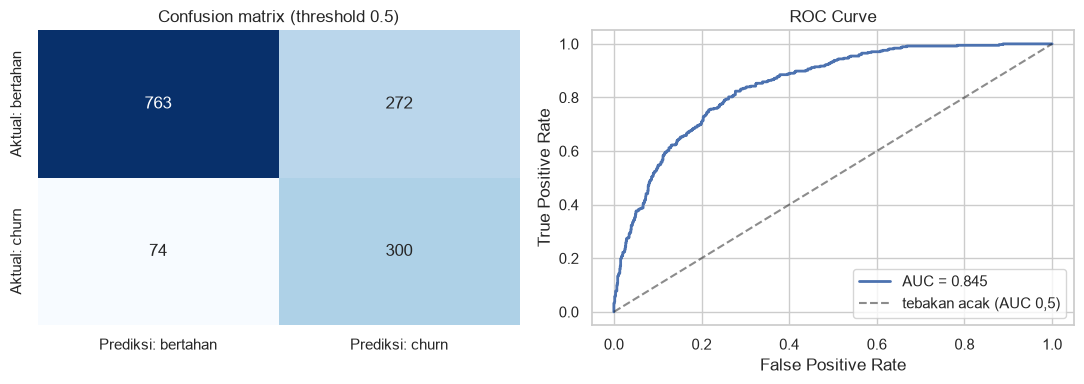

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a1,
            xticklabels=["Prediksi: bertahan", "Prediksi: churn"],
            yticklabels=["Aktual: bertahan", "Aktual: churn"])
a1.set_title(f"Confusion matrix (threshold {threshold})")

fpr, tpr, _ = roc_curve(y_test, proba)
a2.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
a2.plot([0, 1], [0, 1], "k--", alpha=0.5, label="tebakan acak (AUC 0,5)")
a2.set_xlabel("False Positive Rate")
a2.set_ylabel("True Positive Rate")
a2.set_title("ROC Curve")
a2.legend()

plt.tight_layout()
plt.show()

**Hasil di data uji (1.409 pelanggan, 374 di antaranya benar-benar churn):**

| Metrik | Nilai | Artinya |
|---|---|---|
| Accuracy | 0,754 | 75,4% tebakan benar (hampir sama dengan dummy, jadi bukan ukuran utama) |
| **Recall** | **0,802** | **80,2% pelanggan yang akan pergi berhasil ditangkap** |
| Precision | 0,524 | Dari yang ditandai, 52,4% benar-benar pergi |
| F1 | 0,634 | keseimbangan recall & precision |
| ROC-AUC | 0,845 | kemampuan membedakan dua kelas tergolong baik |

Dari confusion matrix:

- **TP = 300** → 300 pelanggan berisiko berhasil diidentifikasi
- **FN = 74** → 74 pelanggan akan pergi tanpa terdeteksi
- **FP = 272** → 272 pelanggan aman ikut dihubungi (biaya kampanye)
- **TN = 763** → 763 pelanggan aman dan tidak diganggu

**Cara membaca untuk orang non-teknis:** dari 374 pelanggan yang benar-benar akan
pergi, model menangkap **300 orang**. Tanpa model, kita tidak punya cara memilih
siapa yang harus dihubungi lebih dulu.

## 6. Perbandingan final di data uji

Cross-validation bagus untuk memilih model, tapi keputusan akhir harus memakai
data uji yang belum pernah dilihat model.

In [9]:
pembanding = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), X_train_sc, X_test_sc),
    "KNN (k=15)": (KNeighborsClassifier(n_neighbors=15), X_train_sc, X_test_sc),
    "Random Forest (tuned)": (rf, X_train, X_test),
}

baris = []
for nama, (m, a, b) in pembanding.items():
    if nama != "Random Forest (tuned)":
        m.fit(a, y_train)
    p = m.predict_proba(b)[:, 1]
    pr = (p >= 0.5).astype(int)
    baris.append({
        "model": nama,
        "recall": round(recall_score(y_test, pr), 3),
        "precision": round(precision_score(y_test, pr), 3),
        "f1": round(f1_score(y_test, pr), 3),
        "auc": round(roc_auc_score(y_test, p), 3),
        "akurasi": round(accuracy_score(y_test, pr), 3),
    })

pd.DataFrame(baris).set_index("model")

,recall,precision,f1,auc,akurasi
model,,,,,
Logistic Regression,0.786,0.507,0.616,0.841,0.740
KNN (k=15),0.535,0.570,0.552,0.808,0.769
Random Forest (tuned),0.802,0.524,0.634,0.845,0.754


| Model | Recall | Precision | F1 | AUC | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0,786 | 0,507 | 0,616 | 0,841 | 0,740 |
| KNN (k=15) | 0,535 | 0,570 | 0,552 | 0,808 | 0,769 |
| **Random Forest (tuned)** | **0,802** | 0,524 | **0,634** | **0,845** | 0,754 |

**Model final: Random Forest hasil tuning.**

Alasannya:
1. Recall tertinggi di data uji (**0,802**) — metrik utama project ini
2. F1 dan AUC juga tertinggi
3. Memberi **feature importance**, yang dibutuhkan untuk rekomendasi bisnis

**Kejujuran yang perlu disampaikan:** LogReg menang di cross-validation (0,801 vs
0,795) dan jauh lebih sederhana. Selisih di data uji hanya 1,6 poin recall — secara
statistik tipis. Kalau mentor bertanya *"kenapa tidak LogReg saja?"*, jawaban yang
jujur: *"keduanya layak; kami memilih RF karena unggul tipis di data uji dan
feature importance-nya lebih mudah diterjemahkan jadi rekomendasi."*

## 7. Fitur mana yang paling menentukan?

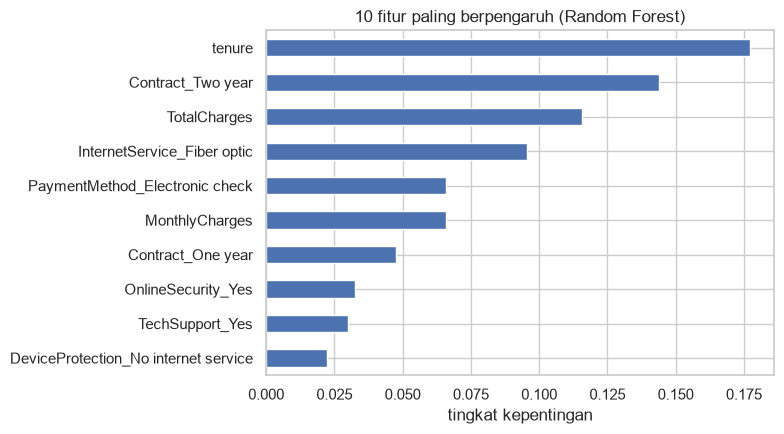

tenure                                  0.1771
Contract_Two year                       0.1440
TotalCharges                            0.1156
InternetService_Fiber optic             0.0954
PaymentMethod_Electronic check          0.0659
MonthlyCharges                          0.0658
Contract_One year                       0.0475
OnlineSecurity_Yes                      0.0324
TechSupport_Yes                         0.0298
DeviceProtection_No internet service    0.0222
dtype: float64

In [10]:
importance = pd.Series(rf.feature_importances_, index=data["features"]).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
importance.head(10).sort_values().plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_title("10 fitur paling berpengaruh (Random Forest)")
ax.set_xlabel("tingkat kepentingan")
plt.tight_layout()
plt.show()

importance.head(10).round(4)

| Peringkat | Fitur | Kepentingan |
|---|---|---|
| 1 | `tenure` | 0,177 |
| 2 | `Contract_Two year` | 0,144 |
| 3 | `TotalCharges` | 0,116 |
| 4 | `InternetService_Fiber optic` | 0,095 |
| 5 | `PaymentMethod_Electronic check` | 0,066 |
| 6 | `MonthlyCharges` | 0,066 |
| 7 | `Contract_One year` | 0,048 |
| 8 | `OnlineSecurity_Yes` | 0,032 |
| 9 | `TechSupport_Yes` | 0,030 |

Tiga teratas semuanya berbicara tentang **lama berlangganan dan komitmen** — bukan
harga. Ini konsisten dengan temuan EDA dan memperkuat cerita utama project.

In [11]:
# arah pengaruh: koefisien Logistic Regression (model yang lebih mudah dibaca)
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train_sc, y_train)
koef = pd.Series(lr.coef_[0], index=data["features"]).sort_values()

print("Menurunkan risiko churn (koefisien negatif):")
print(koef.head(5).round(3).to_string())
print()
print("Menaikkan risiko churn (koefisien positif):")
print(koef.tail(5).round(3).to_string())

Menurunkan risiko churn (koefisien negatif):
tenure               -1.159
MonthlyCharges       -1.039
Contract_Two year    -0.618
Contract_One year    -0.297
OnlineSecurity_Yes   -0.115

Menaikkan risiko churn (koefisien positif):
MultipleLines_Yes              0.201
StreamingTV_Yes                0.273
StreamingMovies_Yes            0.286
TotalCharges                   0.495
InternetService_Fiber optic    0.809


Feature importance hanya bilang **seberapa penting**, bukan **arah pengaruhnya**.
Untuk arah, kita lihat koefisien LogReg:

**Menurunkan risiko:** `tenure`, `Contract_Two year`, `Contract_One year`,
`OnlineSecurity_Yes`, `Dependents_Yes`
**Menaikkan risiko:** `InternetService_Fiber optic`, `TotalCharges`,
`PaymentMethod_Electronic check`

Satu keanehan yang jujur perlu disebut: `MonthlyCharges` berkoefisien **negatif**
(setelah memperhitungkan `TotalCharges`). Ini gejala **multikolinearitas** —
`TotalCharges` ≈ `tenure` × `MonthlyCharges`, jadi ketiganya saling terkait. Model
Random Forest tidak terganggu, tapi interpretasi koefisien satuan harus hati-hati.
Ini masuk daftar limitasi.

## 8. Pembanding paling penting: aturan sederhana tanpa ML

Ini bagian yang membuat project ini berbeda. Sebelum memakai model, kita uji
**aturan manual** yang bisa dibuat siapa pun tanpa machine learning:

> "Tandai pelanggan yang kontraknya bulanan, tenure ≤ 12 bulan, dan tidak punya
> tech support."

In [12]:
# X_test sudah ter-encode, jadi profil asli diambil ulang lewat indeksnya
profil = pd.read_csv(BASE / "data" / "clean" / "churn_clean.csv").loc[X_test.index]

aturan = (
    (profil["Contract"] == "Month-to-month")
    & (profil["tenure"] <= 12)
    & (profil["TechSupport"] == "No")
)

tp_rule = int((aturan & (y_test == 1)).sum())
print("pelanggan ditandai aturan :", int(aturan.sum()))
print("benar-benar churn         :", tp_rule)
print("precision                 :", round(tp_rule / max(int(aturan.sum()), 1), 3))
print("recall                    :", round(tp_rule / y_test.sum(), 3))
print()
print("--- model final ---")
print("pelanggan ditandai model  :", int(pred.sum()))
print("benar-benar churn         :", tp)
print("precision                 :", round(tp / max(int(pred.sum()), 1), 3))
print("recall                    :", round(tp / y_test.sum(), 3))

pelanggan ditandai aturan : 270
benar-benar churn         : 167
precision                 : 0.619
recall                    : 0.447

--- model final ---
pelanggan ditandai model  : 572
benar-benar churn         : 300
precision                 : 0.524
recall                    : 0.802


| Pendekatan | Ditandai | Churn tertangkap | Precision | Recall |
|---|---|---|---|---|
| Aturan sederhana | 270 | 167 | **0,619** | 0,447 |
| **Model Random Forest** | 572 | **300** | 0,524 | **0,802** |

**Ini inti argumen project:** model menangkap **300** pelanggan berisiko, aturan
manual hanya **167** — selisih **133 orang** yang akan hilang tanpa model.

Tapi jujur: precision model lebih rendah (0,524 vs 0,619), artinya lebih banyak
"false alarm". Trade-off-nya: **model lebih baik dalam tidak melewatkan orang**,
aturan lebih baik dalam tidak mengganggu orang yang salah.

Untuk kasus churn, melewatkan orang lebih mahal → model menang. Kalau biaya
kampanye per orang sangat tinggi, aturan sederhana bisa jadi pilihan rasional.
Mengetahui kapan model **tidak** lebih baik adalah bagian dari pemahaman.

## 9. Simpan model

Satu file berisi model + threshold + metrik + daftar fitur, supaya dashboard bisa
memakainya tanpa mengulang training.

In [13]:
MODEL_DIR = BASE / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "churn_model.joblib"

joblib.dump({
    "model": rf,
    "threshold": threshold,
    "features": data["features"],
    "encoder": data["encoder"],
    "scaler": data["scaler"],
    "metrics": {
        "recall": round(float(recall_score(y_test, pred)), 3),
        "precision": round(float(precision_score(y_test, pred)), 3),
        "f1": round(float(f1_score(y_test, pred)), 3),
        "auc": round(float(roc_auc_score(y_test, proba)), 3),
        "accuracy": round(float(accuracy_score(y_test, pred)), 3),
    },
    "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "importance": importance.round(4).to_dict(),
    "best_params": gs.best_params_,
    "n_train": int(len(y_train)),
    "n_test": int(len(y_test)),
    "rule_baseline": {"flagged": int(aturan.sum()), "tp": tp_rule},
}, MODEL_PATH)

print("disimpan:", MODEL_PATH)
print("ukuran  :", round(MODEL_PATH.stat().st_size / 1024, 1), "KB")

disimpan: C:\Users\53\Documents\data sains\machine learning\project ML Supervised\models\churn_model.joblib
ukuran  : 6579.0 KB


In [14]:
cek = joblib.load(MODEL_PATH)
print("isi:", list(cek.keys()))
print()
print("threshold:", cek["threshold"])
print("metrics  :", cek["metrics"])
assert cek["threshold"] == threshold
assert len(cek["features"]) == 30
print()
print("verifikasi lulus")

isi: ['model', 'threshold', 'features', 'encoder', 'scaler', 'metrics', 'confusion', 'importance', 'best_params', 'n_train', 'n_test', 'rule_baseline']

threshold: 0.5
metrics  : {'recall': 0.802, 'precision': 0.524, 'f1': 0.634, 'auc': 0.845, 'accuracy': 0.754}

verifikasi lulus


## 10. Kesimpulan & limitasi

**Yang berhasil:**

1. Model menangkap **80,2%** pelanggan yang akan pergi (recall), dengan AUC 0,845.
2. Model mengalahkan aturan sederhana: **300 vs 167** pelanggan tertangkap.
3. Tiga fitur terpenting (`tenure`, `Contract`, `TotalCharges`) mendukung cerita EDA:
   masalahnya **komitmen**, bukan harga.

**Limitasi yang harus disebut jujur:**

| Limitasi | Dampak |
|---|---|
| Data satu perusahaan, satu waktu | Belum tentu berlaku untuk provider lain |
| Hanya 26,5% churn | Kelas minoritas cukup kecil; precision masih 52,4% |
| 22 profil identik | Potensi kebocoran sangat kecil (0,3%) |
| `TotalCharges` ≈ `tenure` × `MonthlyCharges` | Multikolinearitas, koefisien satuan sulit ditafsirkan |
| Tidak ada data kompetitor/harga pasar | Tidak bisa menjelaskan **alasan** pelanggan pergi |
| Korelasi ≠ sebab-akibat | Tidak bisa bilang "tech support mencegah churn" |

**Yang belum dikerjakan (bisa jadi pengembangan):**

- Uji model pada data tahun berbeda untuk melihat penurunan performa
- Tambahkan biaya kampanye untuk menghitung *expected value* per pelanggan
- Coba XGBoost / LightGBM sebagai pembanding ensemble